Using device: cuda:0
Loading LSTM model architecture...
Loading trained weights from 'weights/pytorch_lstm4_weights_iq_normalized_13claA.pt'...
Model loaded successfully.

Scanning for '.mat' files in 'E:/Project/AMR-Benchmark/output_mat_files_QAM16/'...
Found 48818 files. Will test the first 100 samples.

STARTING BATCH PREDICTION (LSTM with I/Q Normalization)

--- Processing Sample 1/100: segment_000000.mat ---
  -> Predicted Modulation: 16QAM
  -> Confidence: 99.91%

--- Processing Sample 2/100: segment_000001.mat ---
  -> Predicted Modulation: 16QAM
  -> Confidence: 99.94%

--- Processing Sample 3/100: segment_000002.mat ---
  -> Predicted Modulation: 16QAM
  -> Confidence: 99.90%

--- Processing Sample 4/100: segment_000003.mat ---
  -> Predicted Modulation: 16QAM
  -> Confidence: 99.91%

--- Processing Sample 5/100: segment_000004.mat ---
  -> Predicted Modulation: 16QAM
  -> Confidence: 99.88%

--- Processing Sample 6/100: segment_000005.mat ---
  -> Predicted Modulation: 16QAM


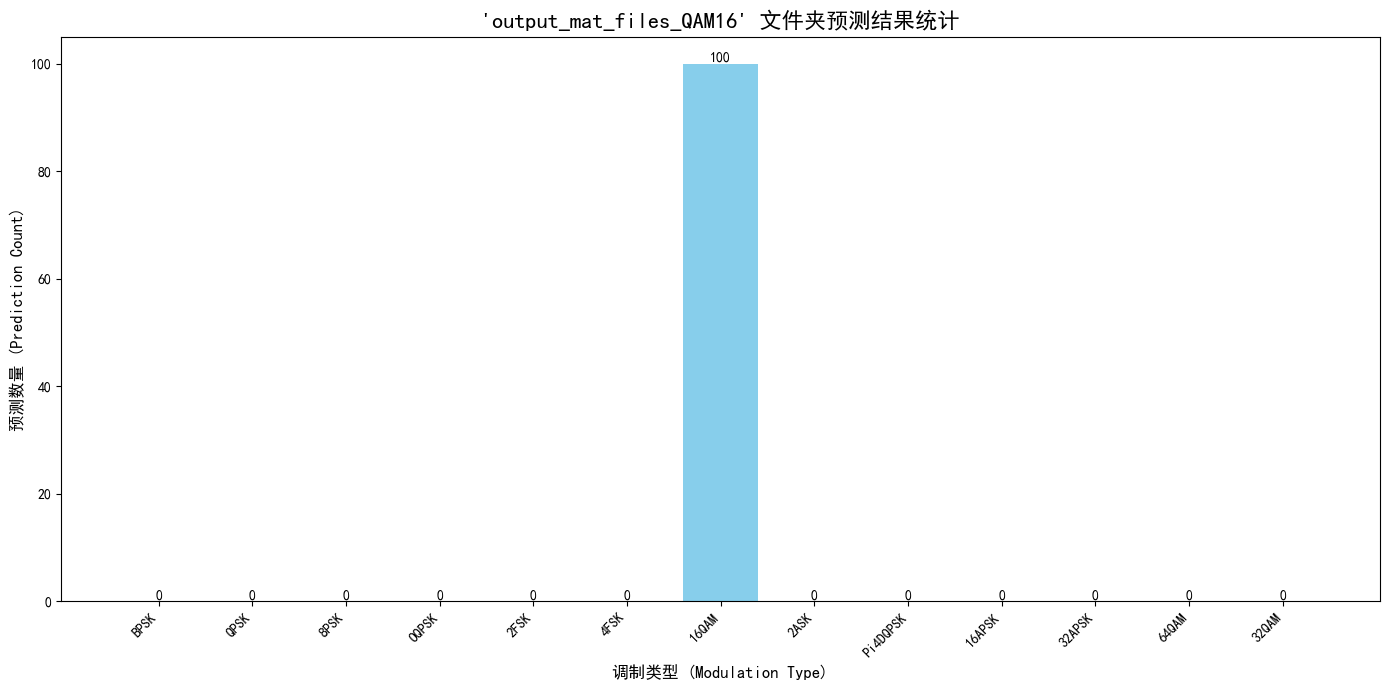

Plot window displayed. Close the plot window to exit the program.


In [2]:
import os
import glob
from collections import Counter
import numpy as np
import pandas as pd
import torch
import torch.nn.functional as F
import h5py
import matplotlib.pyplot as plt
#导入LSTM 模型结构
import LSTM as lstm

try:
    plt.rcParams['font.sans-serif'] = ['SimHei']  # 黑体
    plt.rcParams['axes.unicode_minus'] = False
except Exception as e:
    print(f"无法设置中文字体，可能出现乱码: {e}")

# --- 1. 基本配置 ---
classes = ['BPSK', 'QPSK', '8PSK', 'OQPSK', '2FSK', '4FSK',
             '16QAM', '2ASK', 'Pi4DQPSK', '16APSK', '32APSK', '64QAM','32QAM']

MODEL_WEIGHTS_PATH = 'weights/pytorch_lstm4_weights_iq_normalized_13claA.pt'

# 测试文件
#TEST_DATA_FOLDER = 'E:/Project/AMR-Benchmark/output_mat_files_BPSK/'
#TEST_DATA_FOLDER = 'E:/Project/AMR-Benchmark/output_mat_files_QPSK/'
#TEST_DATA_FOLDER = 'E:/Project/AMR-Benchmark/output_mat_files_PSK8/'

#TEST_DATA_FOLDER = 'E:/Project/AMR-Benchmark/output_mat_files_OQPSK/'
#TEST_DATA_FOLDER = 'E:/Project/AMR-Benchmark/output_mat_files_PI4DQPSK/'

#TEST_DATA_FOLDER = 'E:/Project/AMR-Benchmark/output_mat_files_2FSK/'
#TEST_DATA_FOLDER = 'E:/Project/AMR-Benchmark/output_mat_files_4FSK/'

#TEST_DATA_FOLDER = 'E:/Project/AMR-Benchmark/output_mat_files_ASK2/'

TEST_DATA_FOLDER = 'E:/Project/AMR-Benchmark/output_mat_files_QAM16/'
#TEST_DATA_FOLDER = 'E:/Project/AMR-Benchmark/output_mat_files_QAM64/'



# 指定要测试的样本数量 (N)
NUM_SAMPLES_TO_TEST = 100
# 指定文件扩展名
FILE_EXTENSION = '.mat'

device = torch.device("cuda:0" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device}")


# --- 数据预处理和预测函数 ---

def per_sample_normalize_single(signal_data):
    """
    对单个样本（独立的时间序列）进行归一化，将其缩放到 [-1, 1] 区间。
    输入 shape: (1, 2, 1024)
    """
    min_val = np.min(signal_data)
    max_val = np.max(signal_data)
    range_val = max_val - min_val
    if range_val == 0:
        return np.zeros_like(signal_data)
    normalized_data = 2 * (signal_data - min_val) / range_val - 1
    return normalized_data


def predict_single_signal(model, signal_data, device, class_list):
    """
    对单个经过归一化的 I/Q 信号 (NumPy array) 进行预测。
    输入信号数据形状应为 (1, 2, 1024)。
    """
    if signal_data.shape != (1, 2, 1024):
        raise ValueError(f"Expected signal_data shape (1, 2, 1024), but got {signal_data.shape}")

    model.eval()
    input_tensor = torch.from_numpy(signal_data).float()
    input_tensor = input_tensor.permute(0, 2, 1)
    input_tensor = input_tensor.to(device)

    with torch.no_grad():
        output = model(input_tensor)

    probabilities = F.softmax(output, dim=1)
    confidence, predicted_idx_tensor = torch.max(probabilities, 1)
    predicted_idx = predicted_idx_tensor.item()
    confidence_score = confidence.item()
    predicted_class = class_list[predicted_idx]

    return predicted_class, confidence_score

# --- 绘图函数 ---
def plot_prediction_summary(prediction_counts, class_list, test_folder_path):
    """
    根据预测结果绘制柱状图。

    Args:
        prediction_counts (Counter): 包含每个类别预测次数的 Counter 对象。
        class_list (list): 所有可能的类别名称列表。
        test_folder_path (str): 测试文件夹的路径，用于图表标题。
    """
    # 提取文件夹名称用于标题
    folder_name = os.path.basename(os.path.normpath(test_folder_path))
    
    # 准备绘图数据
    counts = [prediction_counts.get(cls, 0) for cls in class_list]

    # 创建图表
    plt.figure(figsize=(14, 7)) # 设置画布大小，以便容纳所有类别
    bars = plt.bar(class_list, counts, color='skyblue')

    # 在每个柱子上方显示具体数值
    for bar in bars:
        yval = bar.get_height()
        plt.text(bar.get_x() + bar.get_width()/2.0, yval, int(yval), va='bottom', ha='center') # va='bottom' 让文字在柱子上方

    # 添加标题和标签
    plt.title(f"'{folder_name}' 文件夹预测结果统计", fontsize=16)
    plt.xlabel("调制类型 (Modulation Type)", fontsize=12)
    plt.ylabel("预测数量 (Prediction Count)", fontsize=12)
    
    # 旋转x轴标签以防重叠
    plt.xticks(rotation=45, ha='right')
    
    # 调整布局以确保所有内容都可见
    plt.tight_layout()
    
    # 显示图表
    plt.show()


# --- 3. 主执行程序 ---
if __name__ == "__main__":
    if not os.path.exists(MODEL_WEIGHTS_PATH):
        print(f"Error: Model weights not found at '{MODEL_WEIGHTS_PATH}'")
    else:
        # a. 加载 LSTM 模型
        print("Loading LSTM model architecture...")
        model = lstm.build_model(classes=len(classes))
        print(f"Loading trained weights from '{MODEL_WEIGHTS_PATH}'...")
        model.load_state_dict(torch.load(MODEL_WEIGHTS_PATH, map_location=device))
        model.to(device)
        print("Model loaded successfully.")

        # b. 查找并准备测试文件
        print(f"\nScanning for '{FILE_EXTENSION}' files in '{TEST_DATA_FOLDER}'...")
        search_pattern = os.path.join(TEST_DATA_FOLDER, f'*{FILE_EXTENSION}')
        all_files = glob.glob(search_pattern)

        if not all_files:
            print(f"Error: No '{FILE_EXTENSION}' files found in the specified folder.")
            exit()

        files_to_test = all_files[:NUM_SAMPLES_TO_TEST]
        print(f"Found {len(all_files)} files. Will test the first {len(files_to_test)} samples.")

        # c. 循环预测并统计结果
        prediction_counts = Counter()
        print("\n" + "=" * 50)
        print("STARTING BATCH PREDICTION (LSTM with I/Q Normalization)")
        print("=" * 50)

        for i, file_path in enumerate(files_to_test):
            print(f"\n--- Processing Sample {i + 1}/{len(files_to_test)}: {os.path.basename(file_path)} ---")

            try:
                with h5py.File(file_path, 'r') as data_file:
                    single_signal_sample = data_file['data_save'][:]

                if single_signal_sample.shape != (1, 2, 1024):
                    print(f"  [Skipping] Incorrect data shape: {single_signal_sample.shape}. Expected (1, 2, 1024).")
                    continue

                normalized_signal_sample = per_sample_normalize_single(single_signal_sample)

                predicted_modulation, confidence = predict_single_signal(
                    model=model,
                    signal_data=normalized_signal_sample,
                    device=device,
                    class_list=classes
                )

                print(f"  -> Predicted Modulation: {predicted_modulation}")
                print(f"  -> Confidence: {confidence * 100:.2f}%")
                prediction_counts[predicted_modulation] += 1

            except FileNotFoundError:
                print(f"  [Error] Test data file not found at '{file_path}'")
            except Exception as e:
                print(f"  [Error] An error occurred while processing {os.path.basename(file_path)}: {e}")

        # d. 打印最终的统计摘要
        print("\n" + "=" * 50)
        print("                PREDICTION SUMMARY")
        print("=" * 50)

        total_processed = sum(prediction_counts.values())
        print(f"Total samples successfully processed: {total_processed}/{len(files_to_test)}")

        if not prediction_counts:
            print("No successful predictions were made.")
        else:
            print("\nPrediction Counts:")
            for class_name in classes:
                count = prediction_counts.get(class_name, 0)
                print(f"- {class_name:<10}: {count} times")

        print("=" * 50)

        # --- 调用绘图函数，可视化结果 ---
        if total_processed > 0:
            print("\nGenerating prediction summary plot...")
            plot_prediction_summary(prediction_counts, classes, TEST_DATA_FOLDER)
            print("Plot window displayed. Close the plot window to exit the program.")